<a href="https://colab.research.google.com/github/bavithrar2024cse-ops/data-science-24CS032-/blob/main/Machine_Maintenance_Insight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Machine Maintenance Insight")
print("Organization: MechaCare Industrial Systems")
print("Goal: Identify machines requiring maintenance attention")

Machine Maintenance Insight
Organization: MechaCare Industrial Systems
Goal: Identify machines requiring maintenance attention


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


# Machine Maintenance Insight

**Organization:** MechaCare Industrial Systems  
**Sector:** Industry  
**Assessment:** U23AD491 – Data Science | DS Sprint – Skill Based Assessment 2

## Business Problem
Identify operating patterns that indicate industrial machines require maintenance attention.

## Project Objectives
1. Inspect and clean sensor, machine, usage, alarm, and maintenance data.
2. Perform Exploratory Data Analysis (EDA).
3. Identify abnormal sensor readings and recurring alarm patterns.
4. Analyze sensor trends before maintenance and the relationship between load and downtime.
5. Engineer meaningful features for maintenance analysis.
6. Prepare visualizations and business recommendations.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Microsoft Excel
- Google Colab

## Expected Deliverables
- Cleaned dataset
- Python notebook with EDA and feature engineering
- Excel workbook with formulas, charts, and Pivot Tables
- Business-insight presentation

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

print(os.listdir('/content/drive/MyDrive'))


['Screenshot_2025-03-06-15-45-56-66_75372ecd1fda05c59c9af469727b3110.jpg', 'Screenshot_2025-03-06-15-46-16-88_75372ecd1fda05c59c9af469727b3110.jpg', 'Classroom', 'Assignment 2.gdoc', 'Bavithra R(CSE-A).zip', 'py1 (1).py', 'py1.py', 'py2 (1).py', 'py2.py', 'py3 (1).py', 'py3.py', 'py4 (1).py', 'py4.py', 'py5 (1).py', 'py5.py', 'py6 (1).py', 'py6.py', 'Oops 12 programs of day 1 (1).gdoc', 'Oops 12 programs of day 1.gdoc', 'py11 (1).py', 'py11.py', 'py12 (1).py', 'py12.py', 'py13 (1).py', 'py13.py', 'py14 (1).py', 'py14.py', 'py15 (1).py', 'py15.py', 'py16 (1).py', 'py16.py', 'py17 (1).py', 'py17.py', 'py18 (1).py', 'py18.py', 'py19 (1).py', 'py19.py', 'py20 (1).py', 'py20.py', 'py21 (1).py', 'py21.py', 'py22 (1).py', 'py22.py', 'py23 (1).py', 'py23.py', 'py24 (1).py', 'py24.py', 'py25 (1).py', 'py25.py', 'py26 (1).py', 'py26.py', 'py27 (1).py', 'py27.py', 'py28 (1).py', 'py28.py', 'py29 (1).py', 'py29.py', 'py30 (1).py', 'py30.py', 'py31 (1).py', 'py31.py', 'py32 (1).py', 'py32.py', 'py3

In [ ]:

import os

PROJECT_PATH = "/content/drive/MyDrive/Machine_Maintenance_Insight"

print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("Folders inside project:", os.listdir(PROJECT_PATH))


Project folder exists: True
Folders inside project: ['data', 'notebooks', 'excel', 'presentation']


In [ ]:

DATA_PATH = os.path.join(PROJECT_PATH, "data")

print("Data folder exists:", os.path.exists(DATA_PATH))
print("Files currently in data folder:", os.listdir(DATA_PATH))


Data folder exists: True
Files currently in data folder: []


In [ ]:

import os
import pandas as pd

expected_files = [
    "sensor.csv",
    "machines.csv",
    "usage.csv",
    "alarms.csv",
    "maintenance.csv"
]

inventory = []

for filename in expected_files:
    file_path = os.path.join(DATA_PATH, filename)

    inventory.append({
        "File Name": filename,
        "Available": os.path.isfile(file_path),
        "File Path": file_path
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)


,File Name,Available,File Path
0,sensor.csv,False,/content/drive/MyDrive/Machine_Maintenance_Ins...
1,machines.csv,False,/content/drive/MyDrive/Machine_Maintenance_Ins...
2,usage.csv,False,/content/drive/MyDrive/Machine_Maintenance_Ins...
3,alarms.csv,False,/content/drive/MyDrive/Machine_Maintenance_Ins...
4,maintenance.csv,False,/content/drive/MyDrive/Machine_Maintenance_Ins...


In [ ]:

import os
import pandas as pd

def load_dataset(filename):
    file_path = os.path.join(DATA_PATH, filename)

    if not os.path.isfile(file_path):
        print(f"File not found: {filename}")
        print("Please place this file inside the data folder.")
        return None

    df = pd.read_csv(file_path)

    print(f"Successfully loaded: {filename}")
    print(f"Number of rows: {df.shape[0]}")
    print(f"Number of columns: {df.shape[1]}")

    return df


In [ ]:

sensor_df = load_dataset("sensor.csv")


File not found: sensor.csv
Please place this file inside the data folder.


In [ ]:

def inspect_dataset(df, dataset_name):
    if df is None:
        print(f"{dataset_name} is not loaded yet.")
        return

    print(f"DATASET: {dataset_name}")
    print("\n1. First five rows")
    display(df.head())

    print("\n2. Dataset dimensions")
    print(df.shape)

    print("\n3. Column names")
    print(df.columns.tolist())

    print("\n4. Data types")
    print(df.dtypes)

    print("\n5. Missing values")
    print(df.isnull().sum())

    print("\n6. Duplicate rows")
    print(df.duplicated().sum())

    print("\n7. Statistical summary")
    display(df.describe(include="all").T)


In [ ]:

inspect_dataset(sensor_df, "Sensor Dataset")


Sensor Dataset is not loaded yet.


In [ ]:

dataset_files = {
    "sensor": "sensor.csv",
    "machines": "machines.csv",
    "usage": "usage.csv",
    "alarms": "alarms.csv",
    "maintenance": "maintenance.csv"
}

datasets = {}

for dataset_name, filename in dataset_files.items():
    datasets[dataset_name] = load_dataset(filename)

print("\nDataset loading summary")

for dataset_name, df in datasets.items():
    if df is not None:
        print(f"{dataset_name}: Loaded successfully - {df.shape}")
    else:
        print(f"{dataset_name}: Waiting for file")


File not found: sensor.csv
Please place this file inside the data folder.
File not found: machines.csv
Please place this file inside the data folder.
File not found: usage.csv
Please place this file inside the data folder.
File not found: alarms.csv
Please place this file inside the data folder.
File not found: maintenance.csv
Please place this file inside the data folder.

Dataset loading summary
sensor: Waiting for file
machines: Waiting for file
usage: Waiting for file
alarms: Waiting for file
maintenance: Waiting for file


In [ ]:

def data_quality_report(df, dataset_name):
    if df is None:
        print(f"{dataset_name}: Dataset not available yet.")
        return

    report = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Missing Values": df.isnull().sum(),
        "Missing Percentage": (df.isnull().mean() * 100).round(2),
        "Unique Values": df.nunique(),
    })

    print(f"\nData Quality Report: {dataset_name}")
    display(report)

    print("Total rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())


In [ ]:

data_quality_report(datasets["sensor"], "Sensor Dataset")


Sensor Dataset: Dataset not available yet.


In [ ]:

def analyze_dataset(df, name):
    if df is None:
        print(f"{name}: Waiting for the original CSV file.")
        return

    print(f"\n===== {name.upper()} =====")
    print("Shape:", df.shape)
    print("\nColumn types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())
    print("\nStatistical summary:")
    display(df.describe(include="all").T)

for name, df in datasets.items():
    analyze_dataset(df, name)


sensor: Waiting for the original CSV file.
machines: Waiting for the original CSV file.
usage: Waiting for the original CSV file.
alarms: Waiting for the original CSV file.
maintenance: Waiting for the original CSV file.


In [ ]:

import os
import pandas as pd

print("Files found:", os.listdir(DATA_PATH))

files = {
    "sensor": "sensor.csv",
    "machines": "machines.csv",
    "usage": "usage.csv",
    "alarms": "alarms.csv",
    "maintenance": "maintenance.csv"
}

datasets = {}

for name, filename in files.items():
    path = os.path.join(DATA_PATH, filename)
    datasets[name] = pd.read_csv(path)
    print(f"{name}: {datasets[name].shape}")


Files found: ['machines.csv', 'alarms.csv', 'usage.csv', 'maintenance.csv', 'sensor.csv']
sensor: (38, 5)
machines: (5, 4)
usage: (10, 5)
alarms: (13, 3)
maintenance: (6, 4)


In [ ]:

for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print("Missing values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())



--- SENSOR ---
Missing values:
timestamp      0
machine        0
vibration      1
temperature    1
current        0
dtype: int64
Duplicate rows: 1

--- MACHINES ---
Missing values:
machine              0
type                 0
age                  0
installation_date    0
dtype: int64
Duplicate rows: 0

--- USAGE ---
Missing values:
machine    0
date       0
runtime    0
load       0
cycles     0
dtype: int64
Duplicate rows: 0

--- ALARMS ---
Missing values:
machine       0
timestamp     0
alarm_type    0
dtype: int64
Duplicate rows: 1

--- MAINTENANCE ---
Missing values:
machine         0
service_date    0
action          0
downtime        0
dtype: int64
Duplicate rows: 0


In [ ]:

for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print(df.dtypes)
    display(df.head(3))



--- SENSOR ---
timestamp       object
machine         object
vibration      float64
temperature    float64
current        float64
dtype: object


,timestamp,machine,vibration,temperature,current
0,2026-08-01 08:00,M01,2.1,61.0,10.2
1,2026-08-01 10:00,M01,2.4,63.0,10.5
2,2026-08-01 12:00,M01,3.8,72.0,11.4



--- MACHINES ---
machine              object
type                 object
age                   int64
installation_date    object
dtype: object


,machine,type,age,installation_date
0,M01,CNC,8,2018-04-12
1,M02,Pump,5,2021-02-20
2,M03,Compressor,10,2016-09-05



--- USAGE ---
machine     object
date        object
runtime    float64
load       float64
cycles       int64
dtype: object


,machine,date,runtime,load,cycles
0,M01,2026-08-01,10.0,0.85,1200
1,M01,2026-08-02,11.5,0.92,1350
2,M02,2026-08-01,7.0,0.45,900



--- ALARMS ---
machine       object
timestamp     object
alarm_type    object
dtype: object


,machine,timestamp,alarm_type
0,M01,2026-08-01 12:05,High Temperature
1,M01,2026-08-01 14:05,Vibration High
2,M01,2026-08-02 08:05,high temperature



--- MAINTENANCE ---
machine          object
service_date     object
action           object
downtime        float64
dtype: object


,machine,service_date,action,downtime
0,M01,2026-08-03,Bearing replacement,8.0
1,M03,2026-08-03,Cooling system service,12.0
2,M05,2026-08-03,Bearing inspection,5.0


In [ ]:

cleaned = {name: df.copy() for name, df in datasets.items()}

# Remove exact duplicate rows
for name in cleaned:
    cleaned[name] = cleaned[name].drop_duplicates().copy()

# Convert date columns
cleaned["sensor"]["timestamp"] = pd.to_datetime(
    cleaned["sensor"]["timestamp"], errors="coerce"
)
cleaned["machines"]["installation_date"] = pd.to_datetime(
    cleaned["machines"]["installation_date"], errors="coerce"
)
cleaned["alarms"]["timestamp"] = pd.to_datetime(
    cleaned["alarms"]["timestamp"], errors="coerce"
)
cleaned["maintenance"]["service_date"] = pd.to_datetime(
    cleaned["maintenance"]["service_date"], errors="coerce"
)

# Standardize alarm labels
cleaned["alarms"]["alarm_type"] = (
    cleaned["alarms"]["alarm_type"].astype("string").str.strip().str.lower()
)

# Display cleaned dataset sizes
for name, df in cleaned.items():
    print(f"{name}: {df.shape}")


sensor: (37, 5)
machines: (5, 4)
usage: (10, 5)
alarms: (12, 3)
maintenance: (6, 4)


In [ ]:

sensor = cleaned["sensor"]

display(sensor[["vibration", "temperature", "current"]].describe())

print("Missing sensor readings:")
print(sensor[["vibration", "temperature", "current"]].isnull().sum())

print("\nHighest sensor readings:")
display(sensor.nlargest(5, "vibration")[
    ["timestamp", "machine", "vibration", "temperature", "current"]
])


,vibration,temperature,current
count,36.000000,36.000000,37.000000
mean,5.619444,71.583333,12.105405
std,16.114693,43.380954,11.817617
min,1.000000,43.000000,6.800000
25%,1.375000,48.000000,7.600000
50%,2.350000,61.500000,10.100000
75%,4.800000,83.250000,13.100000
max,99.000000,300.000000,80.000000


Missing sensor readings:
vibration      1
temperature    1
current        0
dtype: int64

Highest sensor readings:


,timestamp,machine,vibration,temperature,current
36,2026-08-02 14:00:00,M03,99.0,300.0,80.0
5,2026-08-02 10:00:00,M01,6.8,99.0,14.1
4,2026-08-02 08:00:00,M01,6.4,96.0,13.8
19,2026-08-02 10:00:00,M03,6.1,97.0,15.4
3,2026-08-01 14:00:00,M01,5.9,91.0,13.2


In [ ]:

# 1. Most common alarm types
print("COMMON ALARMS")
display(
    cleaned["alarms"]["alarm_type"]
    .value_counts()
    .rename_axis("alarm_type")
    .reset_index(name="count")
)

# 2. Maintenance records by machine type
maintenance = cleaned["maintenance"].copy()
machines = cleaned["machines"].copy()

maintenance_summary = maintenance.merge(
    machines[["machine", "type"]],
    on="machine",
    how="left"
)

print("MAINTENANCE BY MACHINE TYPE")
display(
    maintenance_summary.groupby("type")
    .agg(
        service_count=("machine", "count"),
        total_downtime=("downtime", "sum"),
        average_downtime=("downtime", "mean")
    )
    .reset_index()
    .sort_values("service_count", ascending=False)
)

# 3. Maintenance records by machine
print("MAINTENANCE BY MACHINE")
display(
    maintenance.groupby("machine")
    .agg(
        service_count=("machine", "count"),
        total_downtime=("downtime", "sum")
    )
    .reset_index()
    .sort_values("total_downtime", ascending=False)
)


COMMON ALARMS


,alarm_type,count
0,high temperature,4
1,vibration high,4
2,overcurrent,2
3,normal,2


MAINTENANCE BY MACHINE TYPE


,type,service_count,total_downtime,average_downtime
0,CNC,2,8.5,4.25
1,Compressor,2,21.0,10.50
2,Pump,2,6.0,3.00


MAINTENANCE BY MACHINE


,machine,service_count,total_downtime
2,M03,2,21.0
0,M01,1,8.0
4,M05,1,5.0
1,M02,1,1.0
3,M04,1,0.5


LOAD VS DOWNTIME


,machine,load,runtime,cycles,total_downtime
5,M03,0.96,13.0,1600,21.0
1,M01,0.92,11.5,1350,8.0
4,M03,0.90,12.0,1500,21.0
0,M01,0.85,10.0,1200,8.0
9,M05,0.80,10.0,1250,5.0
8,M05,0.72,9.0,1100,5.0
3,M02,0.50,7.5,950,1.0
2,M02,0.45,7.0,900,1.0
7,M04,0.42,6.5,750,0.5
6,M04,0.40,6.0,700,0.5


Correlation between load and downtime: 0.815


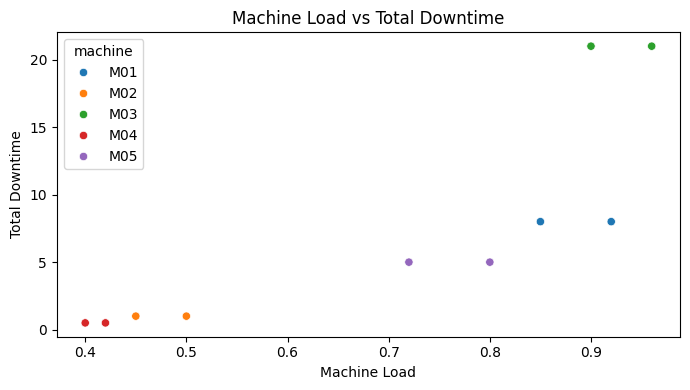

In [ ]:

usage = cleaned["usage"].copy()
maintenance = cleaned["maintenance"].copy()

# Summarize downtime for each machine
downtime = maintenance.groupby("machine", as_index=False).agg(
    total_downtime=("downtime", "sum")
)

# Join usage and downtime by machine
load_analysis = usage.merge(downtime, on="machine", how="left")
load_analysis["total_downtime"] = load_analysis["total_downtime"].fillna(0)

print("LOAD VS DOWNTIME")
display(
    load_analysis[["machine", "load", "runtime", "cycles", "total_downtime"]]
    .sort_values("load", ascending=False)
)

# Calculate correlation
correlation = load_analysis["load"].corr(load_analysis["total_downtime"])
print("Correlation between load and downtime:", round(correlation, 3))

# Plot the relationship
plt.figure(figsize=(7, 4))
sns.scatterplot(data=load_analysis, x="load", y="total_downtime", hue="machine")
plt.title("Machine Load vs Total Downtime")
plt.xlabel("Machine Load")
plt.ylabel("Total Downtime")
plt.tight_layout()
plt.show()


In [ ]:

sensor = cleaned["sensor"].copy()
alarms = cleaned["alarms"].copy()
maintenance = cleaned["maintenance"].copy()

# Summarize alarms by machine
alarm_summary = alarms.groupby("machine").agg(
    alarm_count=("alarm_type", "count"),
    distinct_alarm_types=("alarm_type", "nunique")
).reset_index()

# Summarize sensor readings by machine
sensor_summary = sensor.groupby("machine").agg(
    avg_vibration=("vibration", "mean"),
    max_vibration=("vibration", "max"),
    avg_temperature=("temperature", "mean"),
    max_temperature=("temperature", "max"),
    avg_current=("current", "mean"),
    max_current=("current", "max")
).reset_index()

# Summarize maintenance by machine
maintenance_summary = maintenance.groupby("machine").agg(
    service_count=("machine", "size"),
    total_downtime=("downtime", "sum")
).reset_index()

# Combine summaries
failure_summary = (
    sensor_summary
    .merge(alarm_summary, on="machine", how="left")
    .merge(maintenance_summary, on="machine", how="left")
)

display(failure_summary.round(2))


,machine,avg_vibration,max_vibration,avg_temperature,max_temperature,avg_current,max_current,alarm_count,distinct_alarm_types,service_count,total_downtime
0,M01,4.29,6.8,78.14,99.0,12.00,14.1,4.0,2.0,1,8.0
1,M02,1.44,1.7,49.50,52.0,7.73,8.0,1.0,1.0,1,1.0
2,M03,16.50,99.0,112.25,300.0,22.20,80.0,4.0,2.0,2,21.0
3,M04,1.14,1.3,44.62,46.0,6.96,7.1,NaN,NaN,1,0.5
4,M05,3.17,5.2,68.29,87.0,10.93,13.1,3.0,2.0,1,5.0


In [ ]:

OUTPUT_PATH = os.path.join(PROJECT_PATH, "excel")
os.makedirs(OUTPUT_PATH, exist_ok=True)

failure_summary.to_csv(
    os.path.join(OUTPUT_PATH, "failure_summary.csv"),
    index=False
)

alarm_summary.to_csv(
    os.path.join(OUTPUT_PATH, "alarm_summary.csv"),
    index=False
)

maintenance_summary.to_csv(
    os.path.join(OUTPUT_PATH, "maintenance_summary.csv"),
    index=False
)

print("Analysis summaries saved to:", OUTPUT_PATH)


Analysis summaries saved to: /content/drive/MyDrive/Machine_Maintenance_Insight/excel
